In [22]:
import pandas as pd
import numpy as np
from pathlib import Path
source_path  = Path.cwd().parent / "资料-pd"


#df =  pd.read_csv(source_path / "weather_withna.csv",keep_default_na=False, na_values=["2015-12-31"])
df = pd.read_csv(source_path / "weather_withna.csv")


In [23]:
df.tail(10)

,date,precipitation,temp_max,temp_min,wind,weather
1451,2015-12-22,NaN,NaN,NaN,NaN,NaN
1452,2015-12-23,NaN,NaN,NaN,NaN,NaN
1453,2015-12-24,NaN,NaN,NaN,NaN,NaN
1454,2015-12-25,NaN,NaN,NaN,NaN,NaN
1455,2015-12-26,NaN,NaN,NaN,NaN,NaN
1456,2015-12-27,NaN,NaN,NaN,NaN,NaN
1457,2015-12-28,NaN,NaN,NaN,NaN,NaN
1458,2015-12-29,NaN,NaN,NaN,NaN,NaN
1459,2015-12-30,NaN,NaN,NaN,NaN,NaN
1460,2015-12-31,20.6,12.2,5.0,3.8,rain


In [25]:
print(df.isnull().sum())

date               0
precipitation    303
temp_max         303
temp_min         303
wind             303
weather          303
dtype: int64


<Axes: >

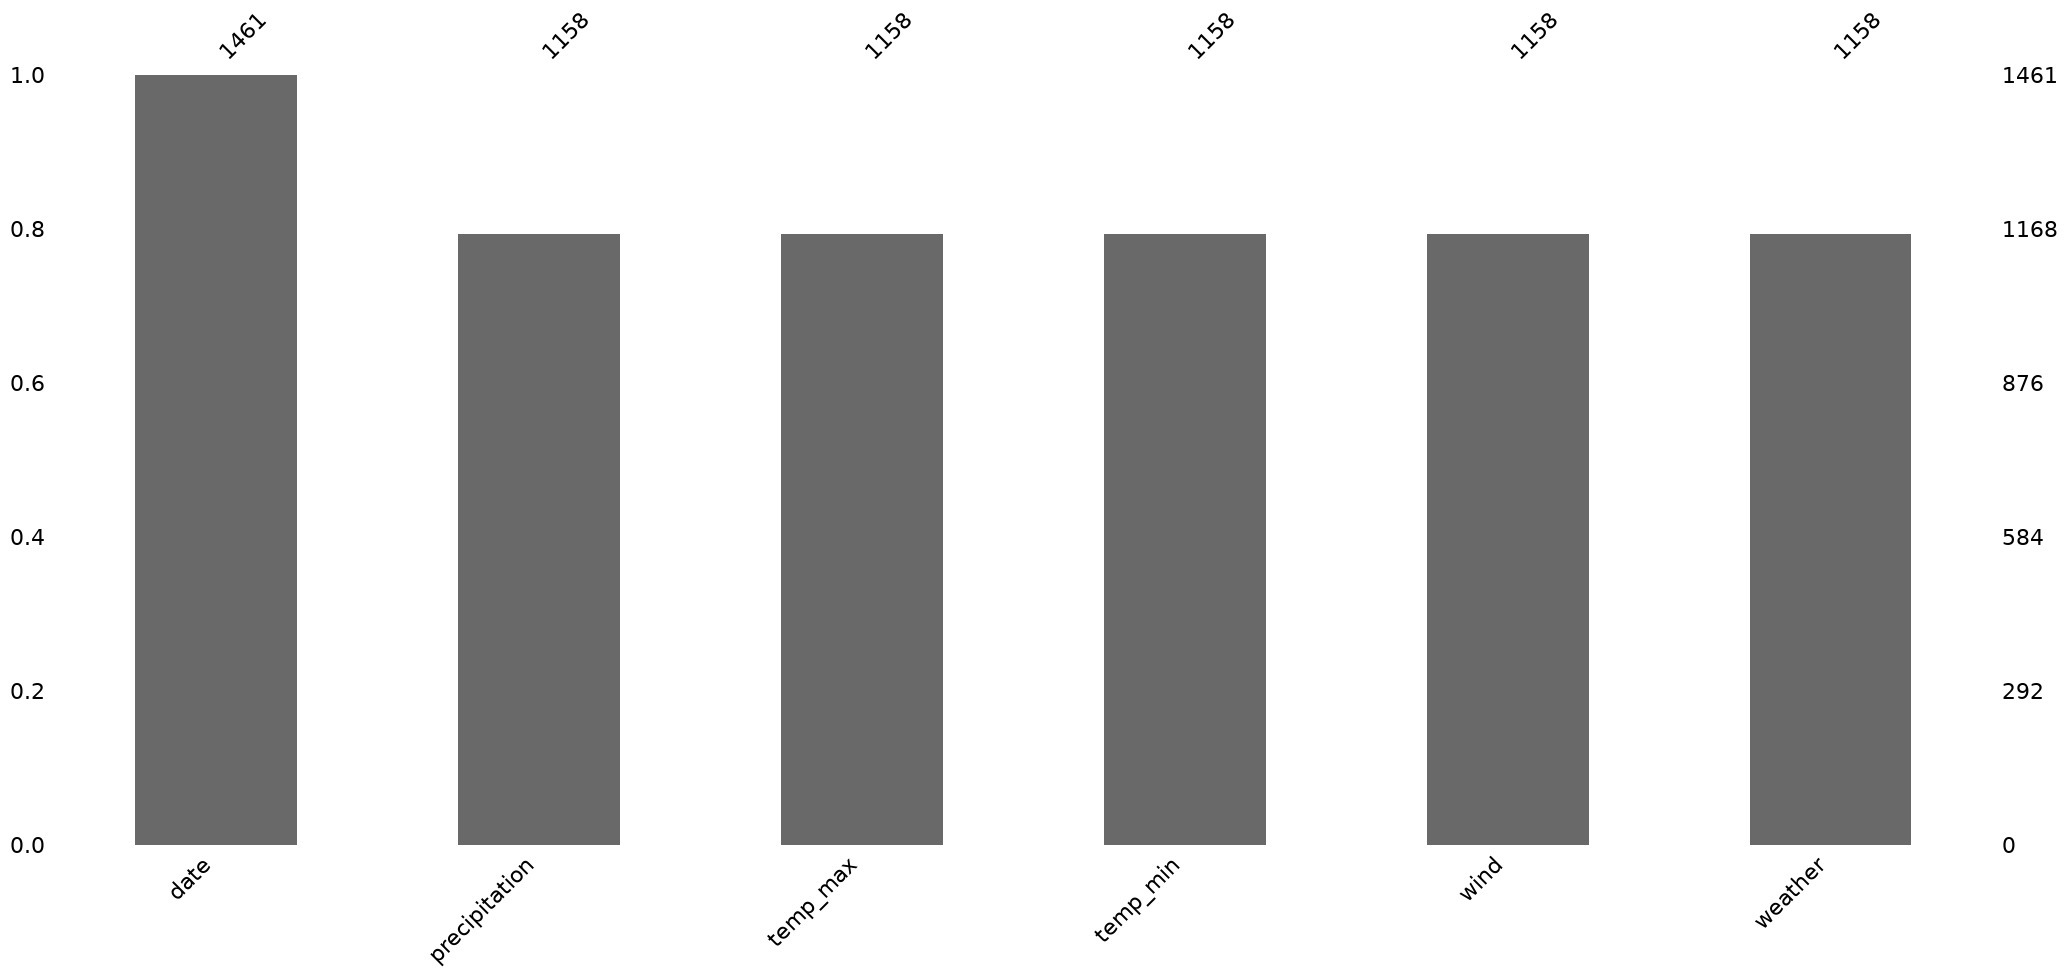

In [27]:
import missingno as msno  # 这是缺失值可视化包
msno.bar(df)


<Axes: >

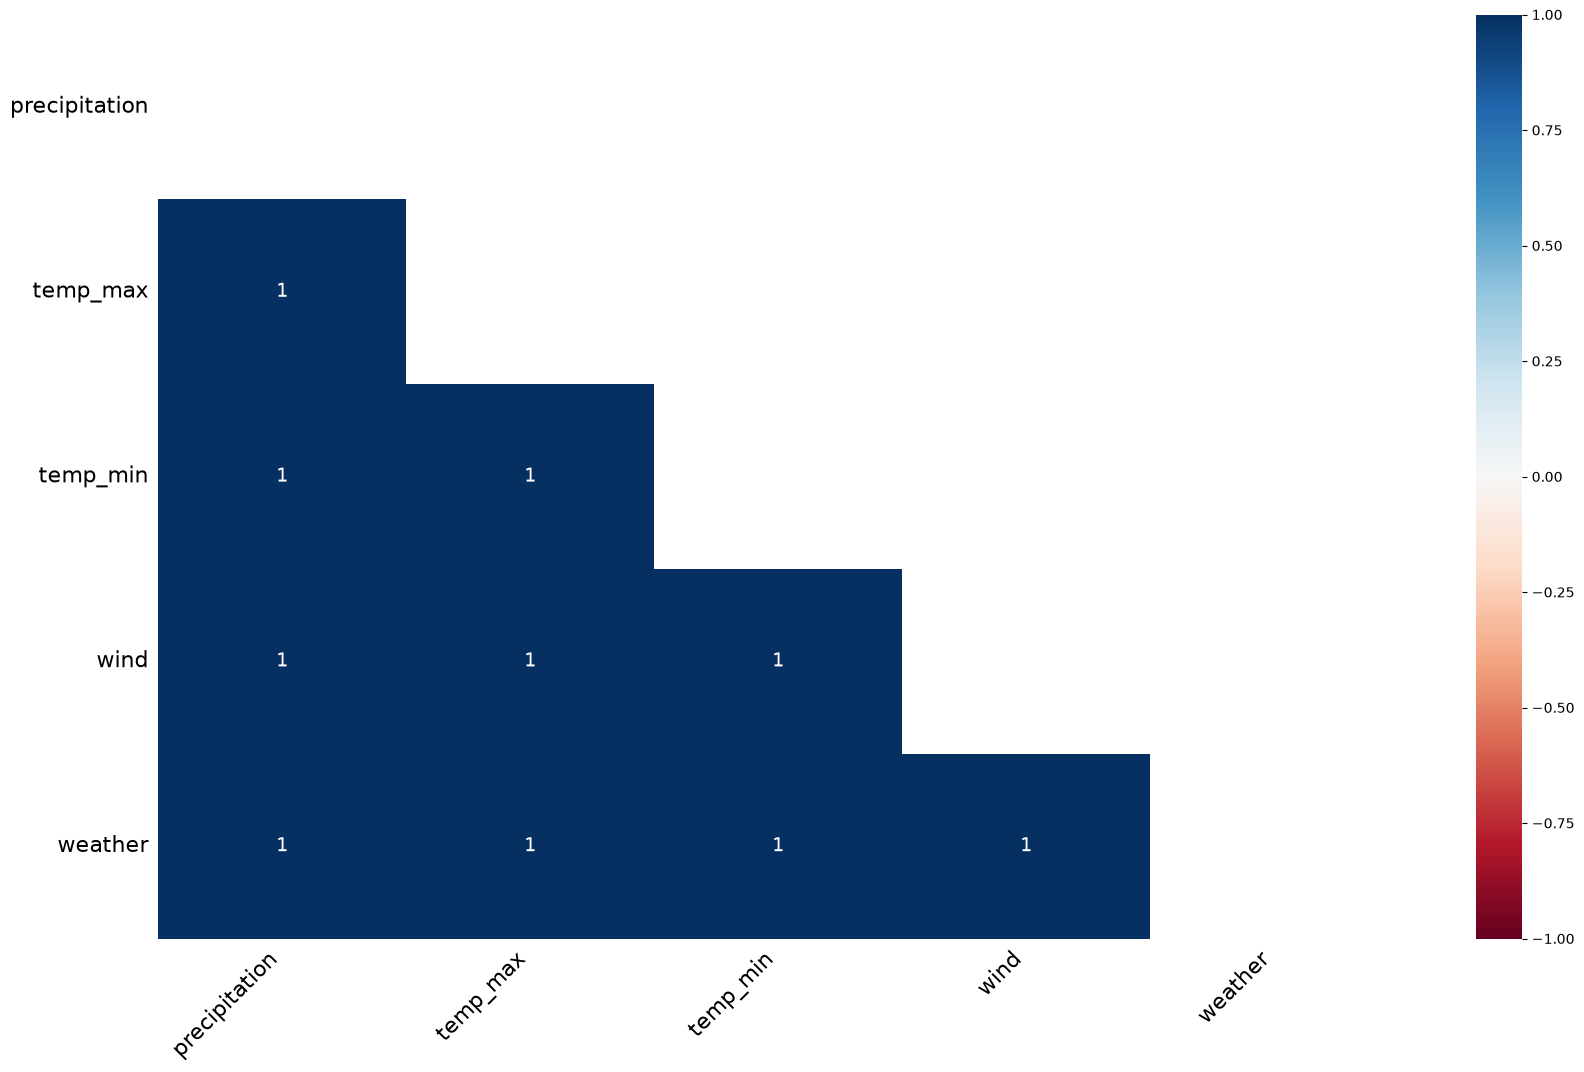

In [28]:
msno.heatmap(df)


In [29]:
s = pd.Series([1,2,3,4,5,6,None,pd.NA])

In [31]:
s.dropna()

0    1
1    2
2    3
3    4
4    5
5    6
dtype: object

In [38]:
df = pd.DataFrame([[1, pd.NA, 2], [2, 3, 5], [pd.NA, 4, 6]])
df.dropna(axis=0) # 丢弃为NA的行
df.dropna(axis=1) # 丢弃为NA的列

,2
0,2
1,5
2,6


In [39]:
df = pd.DataFrame([[1, pd.NA, 2], [pd.NA, pd.NA, 5], [pd.NA, pd.NA, pd.NA]])

In [40]:
# 只删除全部为Na的行
df.dropna(how='all',axis=0)


,0,1,2
0,1,<NA>,2
1,<NA>,<NA>,5


In [41]:
# 至少有两个不是Na
df.dropna(thresh=2,axis=0)


,0,1,2
0,1,<NA>,2


In [43]:
df = pd.DataFrame([[1, pd.NA, 2], [pd.NA, pd.NA, 5], [pd.NA, pd.NA, pd.NA]] )
df



,0,1,2
0,1,<NA>,2
1,<NA>,<NA>,5
2,<NA>,<NA>,<NA>


In [44]:
# 如果0列有缺省值就删除
df.dropna(subset=[0])


,0,1,2
0,1,<NA>,2


In [45]:
df


,0,1,2
0,1,<NA>,2
1,<NA>,<NA>,5
2,<NA>,<NA>,<NA>


### 填充缺省值

In [46]:
df = pd.read_csv(source_path / "weather_withna.csv")

In [48]:
df.tail(10)

,date,precipitation,temp_max,temp_min,wind,weather
1451,2015-12-22,NaN,NaN,NaN,NaN,NaN
1452,2015-12-23,NaN,NaN,NaN,NaN,NaN
1453,2015-12-24,NaN,NaN,NaN,NaN,NaN
1454,2015-12-25,NaN,NaN,NaN,NaN,NaN
1455,2015-12-26,NaN,NaN,NaN,NaN,NaN
1456,2015-12-27,NaN,NaN,NaN,NaN,NaN
1457,2015-12-28,NaN,NaN,NaN,NaN,NaN
1458,2015-12-29,NaN,NaN,NaN,NaN,NaN
1459,2015-12-30,NaN,NaN,NaN,NaN,NaN
1460,2015-12-31,20.6,12.2,5.0,3.8,rain


In [49]:
df.fillna(0).tail()

/var/folders/d_/79_wtvyd1_dckhlrqzx0typ00000gn/T/ipykernel_57574/456510289.py:1: Pandas4Warning: 'int' is not supported as a fill value for str dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  df.fillna(0).tail()


,date,precipitation,temp_max,temp_min,wind,weather
1456,2015-12-27,0.0,0.0,0.0,0.0,0
1457,2015-12-28,0.0,0.0,0.0,0.0,0
1458,2015-12-29,0.0,0.0,0.0,0.0,0
1459,2015-12-30,0.0,0.0,0.0,0.0,0
1460,2015-12-31,20.6,12.2,5.0,3.8,rain


In [50]:
# 使用字典来填充
df.fillna({"precipitation": 19, "temp_max": 3.0, "temp_min": 3.0, "wind": 0, "weather": "rain"})


,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain
...,...,...,...,...,...,...
1456,2015-12-27,19.0,3.0,3.0,0.0,rain
1457,2015-12-28,19.0,3.0,3.0,0.0,rain
1458,2015-12-29,19.0,3.0,3.0,0.0,rain
1459,2015-12-30,19.0,3.0,3.0,0.0,rain


In [51]:
# 最佳方式用平均值填充
df["temp_max"].fillna(df["temp_max"].mean()).tail()


1456    15.851468
1457    15.851468
1458    15.851468
1459    15.851468
1460    12.200000
Name: temp_max, dtype: float64

In [52]:
df.fillna(df[["precipitation", "temp_max", "temp_min", "wind"]].mean()).tail()


,date,precipitation,temp_max,temp_min,wind,weather
1456,2015-12-27,3.052332,15.851468,7.877202,3.242055,NaN
1457,2015-12-28,3.052332,15.851468,7.877202,3.242055,NaN
1458,2015-12-29,3.052332,15.851468,7.877202,3.242055,NaN
1459,2015-12-30,3.052332,15.851468,7.877202,3.242055,NaN
1460,2015-12-31,20.600000,12.200000,5.000000,3.800000,rain


In [54]:
# 使用前后有效值填充 ffill   bfill
df.ffill().tail()

,date,precipitation,temp_max,temp_min,wind,weather
1456,2015-12-27,0.0,11.1,4.4,4.8,sun
1457,2015-12-28,0.0,11.1,4.4,4.8,sun
1458,2015-12-29,0.0,11.1,4.4,4.8,sun
1459,2015-12-30,0.0,11.1,4.4,4.8,sun
1460,2015-12-31,20.6,12.2,5.0,3.8,rain


In [55]:
df.bfill().tail() # 用前后的有效值填充


,date,precipitation,temp_max,temp_min,wind,weather
1456,2015-12-27,20.6,12.2,5.0,3.8,rain
1457,2015-12-28,20.6,12.2,5.0,3.8,rain
1458,2015-12-29,20.6,12.2,5.0,3.8,rain
1459,2015-12-30,20.6,12.2,5.0,3.8,rain
1460,2015-12-31,20.6,12.2,5.0,3.8,rain


In [59]:
# 通过线性插值填充
# interpolate
# linear  基于两点之间的直线来评估缺失值
# time   适合时间序列数据，会考虑时间间隔进行插值
# polynomial  使用多项式来插值

In [60]:
s = pd.Series([1, np.nan, 3, 4, np.nan, 6])

In [65]:
s.interpolate(method='linear')

0    1.0
1    2.0
2    3.0
3    4.0
4    5.0
5    6.0
dtype: float64

### pandas 的apply 函数



In [67]:
s = pd.Series([10, 20, 30])
s.apply(lambda x: x * 2) # 要传入一个函数


0    20
1    40
2    60
dtype: int64

In [68]:
def  func1(item,p):
    return item * p

s.apply(func1,p=2)   # 函数也要传递参数的情况



0    20
1    40
2    60
dtype: int64